In [1]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
if torch.cuda.is_available():
    device = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.9.1 | urządzenie: mps


## Dane CIFAR-10

In [2]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))


from torch.utils.data import random_split

train_set, val_set = random_split(
    train_ds, [45_000, 5_000], generator=torch.Generator().manual_seed(0)
)
BATCH_SIZE = 128

def make_train_loader():
    return DataLoader(
        train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(0),
    )

val_dl = DataLoader(val_set, batch_size=256, num_workers=0)
test_dl = DataLoader(test_ds, batch_size=256, num_workers=0)
print(f"Podział: trening {len(train_set)}, walidacja {len(val_set)}, test {len(test_ds)}")

Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 50000 | Test: 10000
Podział: trening 45000, walidacja 5000, test 10000


## Modele MLP i CNN

In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x): return self.net(x)

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64))  # 32x32 -> 8x8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),
        )
    def forward(self, x): return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters())
print("Parametry MLP:", f"{count_params(MLP()):,}")
print("Parametry CNN:", f"{count_params(SimpleCNN()):,}")

Parametry MLP: 1,707,274
Parametry CNN: 1,117,354


## Trening i walidacja

In [4]:
from copy import deepcopy

def evaluate(model, loader):
    model.eval()
    correct = torch.zeros((), dtype=torch.int32, device=device)
    total = 0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum(dtype=torch.int32)
            total += labels.numel()
    return correct.item() / total

def synchronize():
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()

def train_model(model, epochs, lr):
    model = model.to(device)
    loader = make_train_loader()
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    best_accuracy = -1.0
    synchronize()
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()
        accuracy = evaluate(model, val_dl)
        history.append(accuracy)
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())
        print(f"Epoka {epoch:2d}/{epochs} | accuracy wal. {accuracy:.2%}", flush=True)
    synchronize()
    elapsed = time.perf_counter() - start
    model.load_state_dict(best_weights)
    return history, elapsed, best_epoch

## Trening MLP i CNN

In [6]:
EPOCHS = 10
LR = 0.001

torch.manual_seed(0)
print("MLP", flush=True)
mlp = MLP()
acc_mlp, t_mlp, epoch_mlp = train_model(mlp, EPOCHS, LR)

torch.manual_seed(0)
print("CNN", flush=True)
cnn = SimpleCNN()
acc_cnn, t_cnn, epoch_cnn = train_model(cnn, EPOCHS, LR)

MLP
Epoka  1/10 | accuracy wal. 43.36%
Epoka  2/10 | accuracy wal. 47.98%
Epoka  3/10 | accuracy wal. 49.96%
Epoka  4/10 | accuracy wal. 50.52%
Epoka  5/10 | accuracy wal. 50.30%
Epoka  6/10 | accuracy wal. 51.10%
Epoka  7/10 | accuracy wal. 51.20%
Epoka  8/10 | accuracy wal. 51.70%
Epoka  9/10 | accuracy wal. 52.78%
Epoka 10/10 | accuracy wal. 51.56%
CNN
Epoka  1/10 | accuracy wal. 59.60%
Epoka  2/10 | accuracy wal. 68.34%
Epoka  3/10 | accuracy wal. 69.82%
Epoka  4/10 | accuracy wal. 73.02%
Epoka  5/10 | accuracy wal. 75.66%
Epoka  6/10 | accuracy wal. 75.16%
Epoka  7/10 | accuracy wal. 75.38%
Epoka  8/10 | accuracy wal. 77.32%
Epoka  9/10 | accuracy wal. 78.58%
Epoka 10/10 | accuracy wal. 77.38%


## Wyniki

Adam | LR=0.001 | batch size=128 | epoki=10
Model  |  Parametry |     Test |  Czas [s] | Wybrana epoka
MLP    |  1,707,274 |   52.99% |      34.8 |             9
CNN    |  1,117,354 |   78.87% |      99.0 |             9


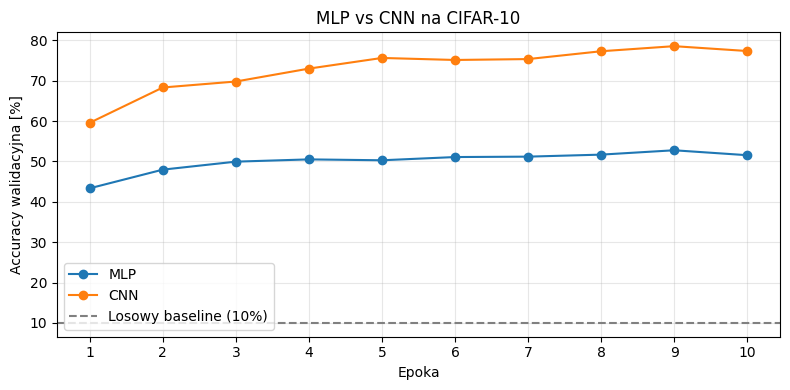

In [7]:
test_mlp = evaluate(mlp, test_dl)
test_cnn = evaluate(cnn, test_dl)

print(f"Adam | LR={LR} | batch size={BATCH_SIZE} | epoki={EPOCHS}")
print(f"{'Model':<6} | {'Parametry':>10} | {'Test':>8} | {'Czas [s]':>9} | {'Wybrana epoka':>13}")

for name, model, accuracy, elapsed, epoch in [
    ("MLP", mlp, test_mlp, t_mlp, epoch_mlp),
    ("CNN", cnn, test_cnn, t_cnn, epoch_cnn),
]:
    print(f"{name:<6} | {count_params(model):>10,} | {accuracy:>8.2%} | {elapsed:>9.1f} | {epoch:>13}")

epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(epochs, [100 * acc for acc in acc_mlp], "o-", label="MLP")
ax.plot(epochs, [100 * acc for acc in acc_cnn], "o-", label="CNN")
ax.axhline(10, color="gray", linestyle="--", label="Losowy baseline (10%)")
ax.set(
    xlabel="Epoka",
    ylabel="Accuracy walidacyjna [%]",
    title="MLP vs CNN na CIFAR-10",
)
ax.set_xticks(list(epochs))
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("lab04_accuracy.png", dpi=160)
plt.show()